In [2]:
from pca_utils import *

# Import data

In [4]:
#path1 = "../data/020226_MGS.csv"
path2 = "../data/140226_MGS.csv"
path3 = "../data/190226_MGS.csv"

#df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)
df3 = pd.read_csv(path3)

#df1["experiment"] = "020226"
df2["experiment"] = "140226"
df3["experiment"] = "190226"

combined_df = pd.concat(
    [df2, df3],
    ignore_index=True
)

combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 2:11] = combined_df.iloc[:, 2:11].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])


Number of cells is: 369


### Clean data

In [ ]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

In [ ]:
df.to_csv("all_MGS.csv")

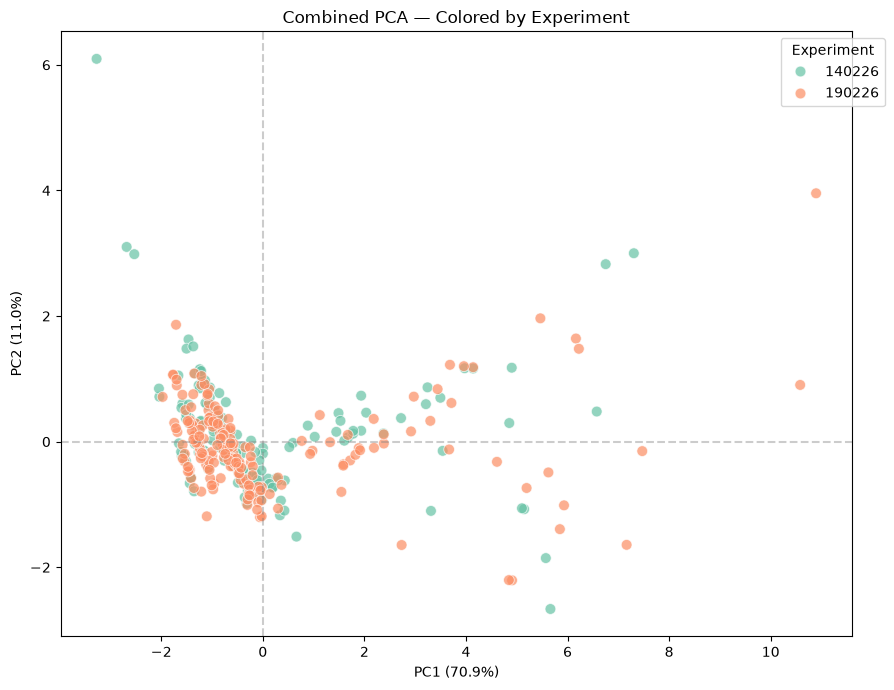

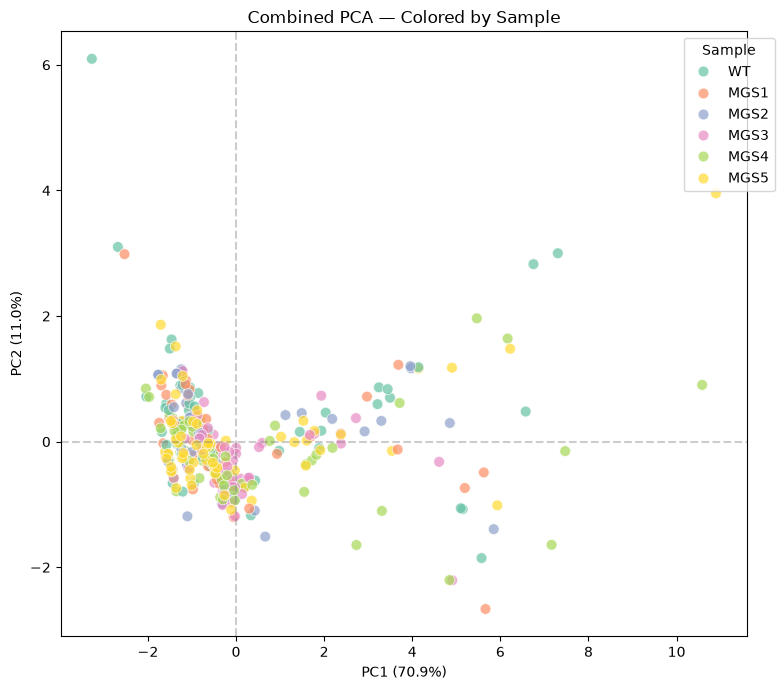

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Features for PCA
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Prepare data
pca_df = df.dropna(
    subset=features + ["experiment", "sample"]
).copy()

pca_df["experiment"] = pca_df["experiment"].astype(str)

# Standardize ALL experiments together
X = pca_df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit ONE PCA using all cells
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

# Explained variance
explained = pca.explained_variance_ratio_ * 100

# Plot PCA by experiment
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="experiment",
    palette="Set2",
    s=60,
    alpha=0.7
)

plt.axhline(0, color="gray", linestyle="--", alpha=0.4)
plt.axvline(0, color="gray", linestyle="--", alpha=0.4)

plt.xlabel(f"PC1 ({explained[0]:.1f}%)")
plt.ylabel(f"PC2 ({explained[1]:.1f}%)")
plt.title("Combined PCA — Colored by Experiment")

plt.legend(title="Experiment", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# Plot the SAME PCA by sample
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="sample",
    palette="Set2",
    s=60,
    alpha=0.7
)

plt.axhline(0, color="gray", linestyle="--", alpha=0.4)
plt.axvline(0, color="gray", linestyle="--", alpha=0.4)

plt.xlabel(f"PC1 ({explained[0]:.1f}%)")
plt.ylabel(f"PC2 ({explained[1]:.1f}%)")
plt.title("Combined PCA — Colored by Sample")

plt.legend(title="Sample", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [6]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2"]
)

print(loadings.round(3))

                            PC1    PC2
n_foci                   -0.329  0.758
equivalent_diameter_area  0.457  0.301
eccentricity             -0.418  0.189
perimeter                 0.449  0.333
solidity                 -0.383 -0.360
mean_intensity            0.400 -0.241


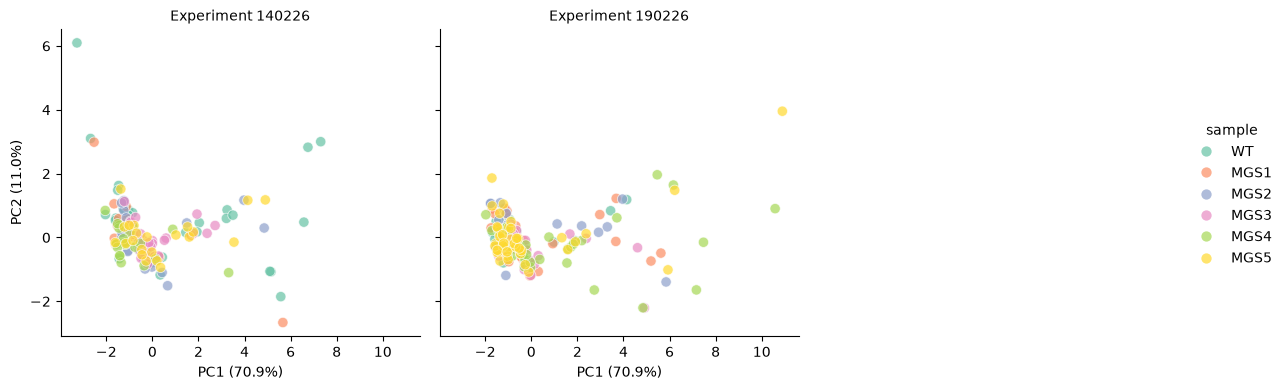

In [7]:
g = sns.relplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="sample",
    col="experiment",
    col_wrap=3,
    palette="Set2",
    kind="scatter",
    alpha=0.7,
    s=55,
    height=4,
    facet_kws={"sharex": True, "sharey": True}
)

g.set_axis_labels(
    f"PC1 ({explained[0]:.1f}%)",
    f"PC2 ({explained[1]:.1f}%)"
)

g.set_titles("Experiment {col_name}")

plt.show()

# Correlation analysis

In [8]:
# Select numerical columns
df_numeric = df.select_dtypes(include=np.number)

# Calculate Spearman correlation
corr = df_numeric.corr(method="spearman")

display(corr.round(3))

,unnamed: 0,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity
unnamed: 0,1.000,-0.117,-0.007,-0.007,0.007,-0.024,-0.033,0.053,0.052,0.055
n_foci,-0.117,1.000,-0.626,-0.626,0.638,0.604,-0.584,-0.719,-0.725,-0.712
area,-0.007,-0.626,1.000,1.000,-0.841,-0.752,0.856,0.726,0.734,0.702
equivalent_diameter_area,-0.007,-0.626,1.000,1.000,-0.841,-0.752,0.856,0.726,0.734,0.702
eccentricity,0.007,0.638,-0.841,-0.841,1.000,0.656,-0.956,-0.707,-0.715,-0.679
solidity,-0.024,0.604,-0.752,-0.752,0.656,1.000,-0.684,-0.614,-0.623,-0.603
perimeter,-0.033,-0.584,0.856,0.856,-0.956,-0.684,1.000,0.701,0.709,0.672
mean_intensity,0.053,-0.719,0.726,0.726,-0.707,-0.614,0.701,1.000,0.999,0.997
max_intensity,0.052,-0.725,0.734,0.734,-0.715,-0.623,0.709,0.999,1.000,0.996
min_intensity,0.055,-0.712,0.702,0.702,-0.679,-0.603,0.672,0.997,0.996,1.000


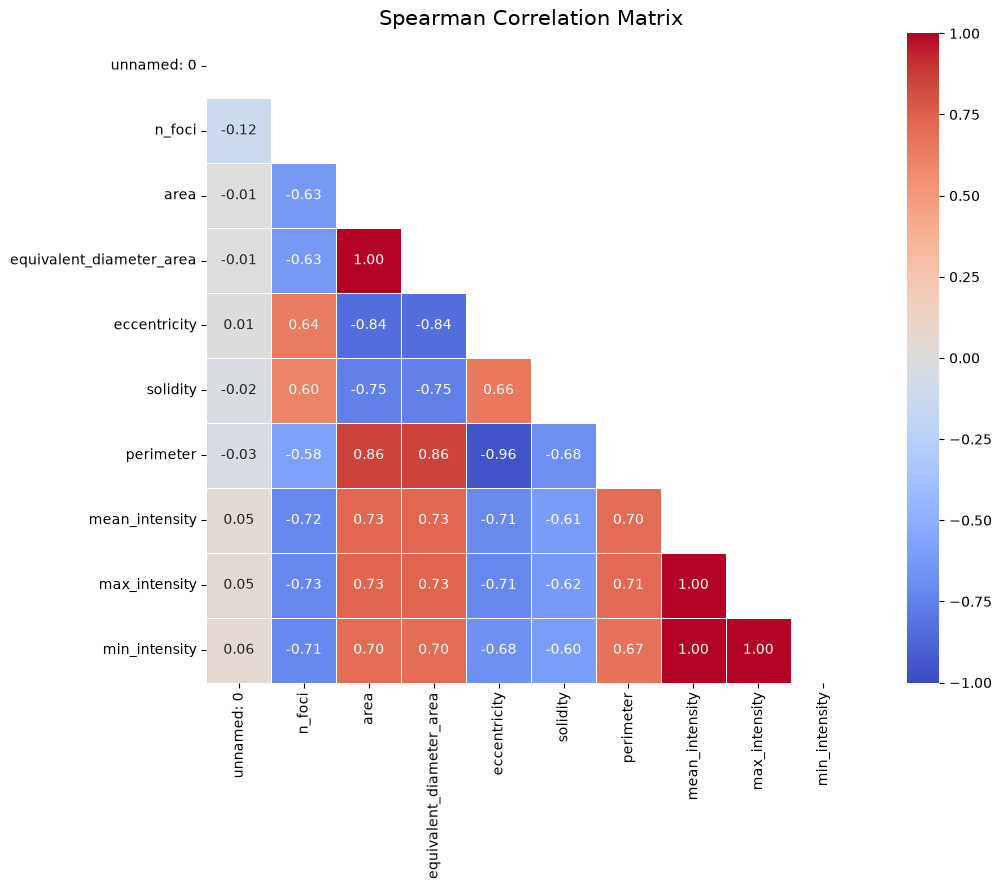

In [9]:
plt.figure(figsize=(12, 9))

# Show only lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

## Graphs

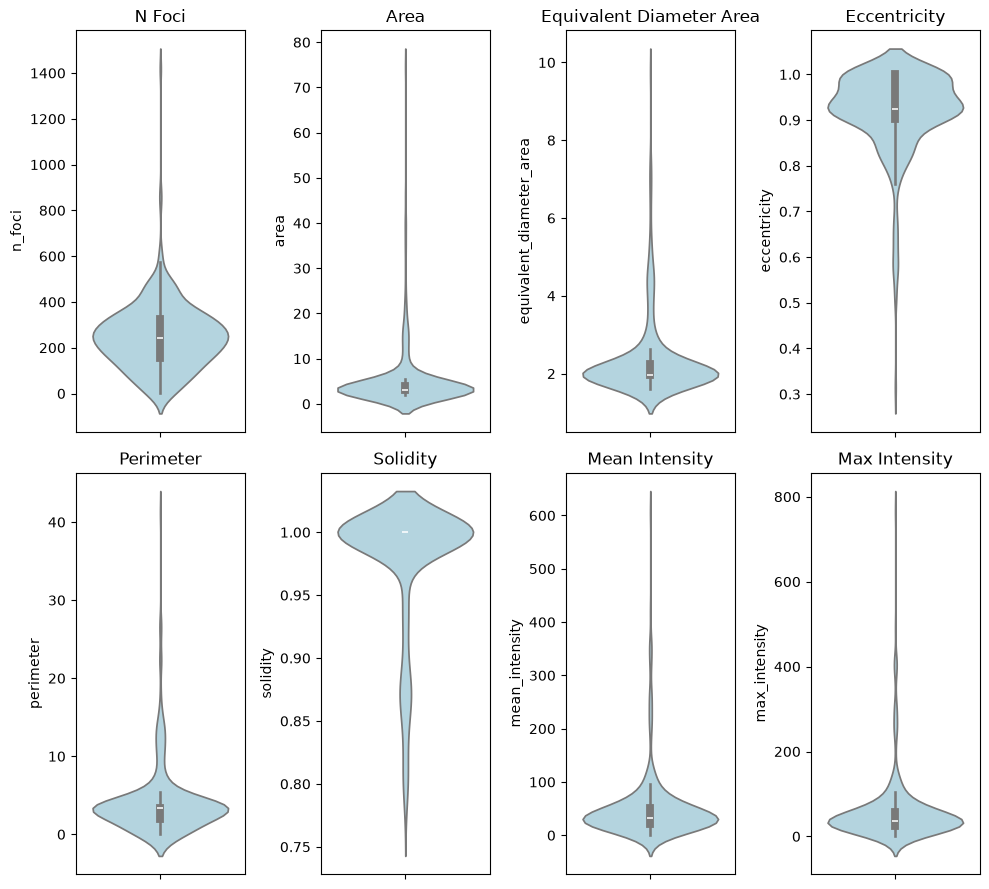

In [10]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(2, 4, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [11]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
    #"min_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

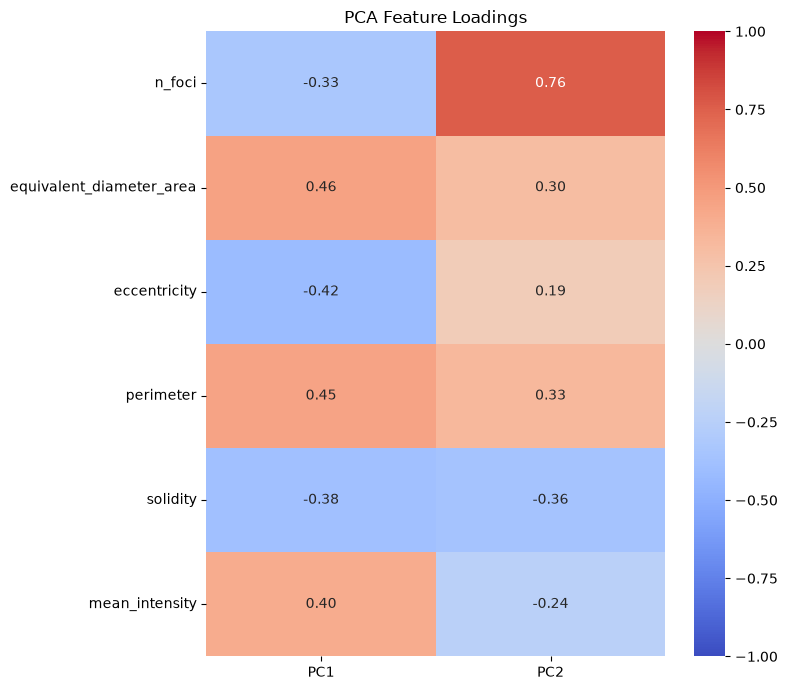

In [12]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [13]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS1   -0.167400  0.012652
MGS2   -0.192846 -0.009097
MGS3    0.015496 -0.238269
MGS4    0.339260 -0.201438
MGS5    0.009648  0.033970
WT     -0.033829  0.291280


In [ ]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

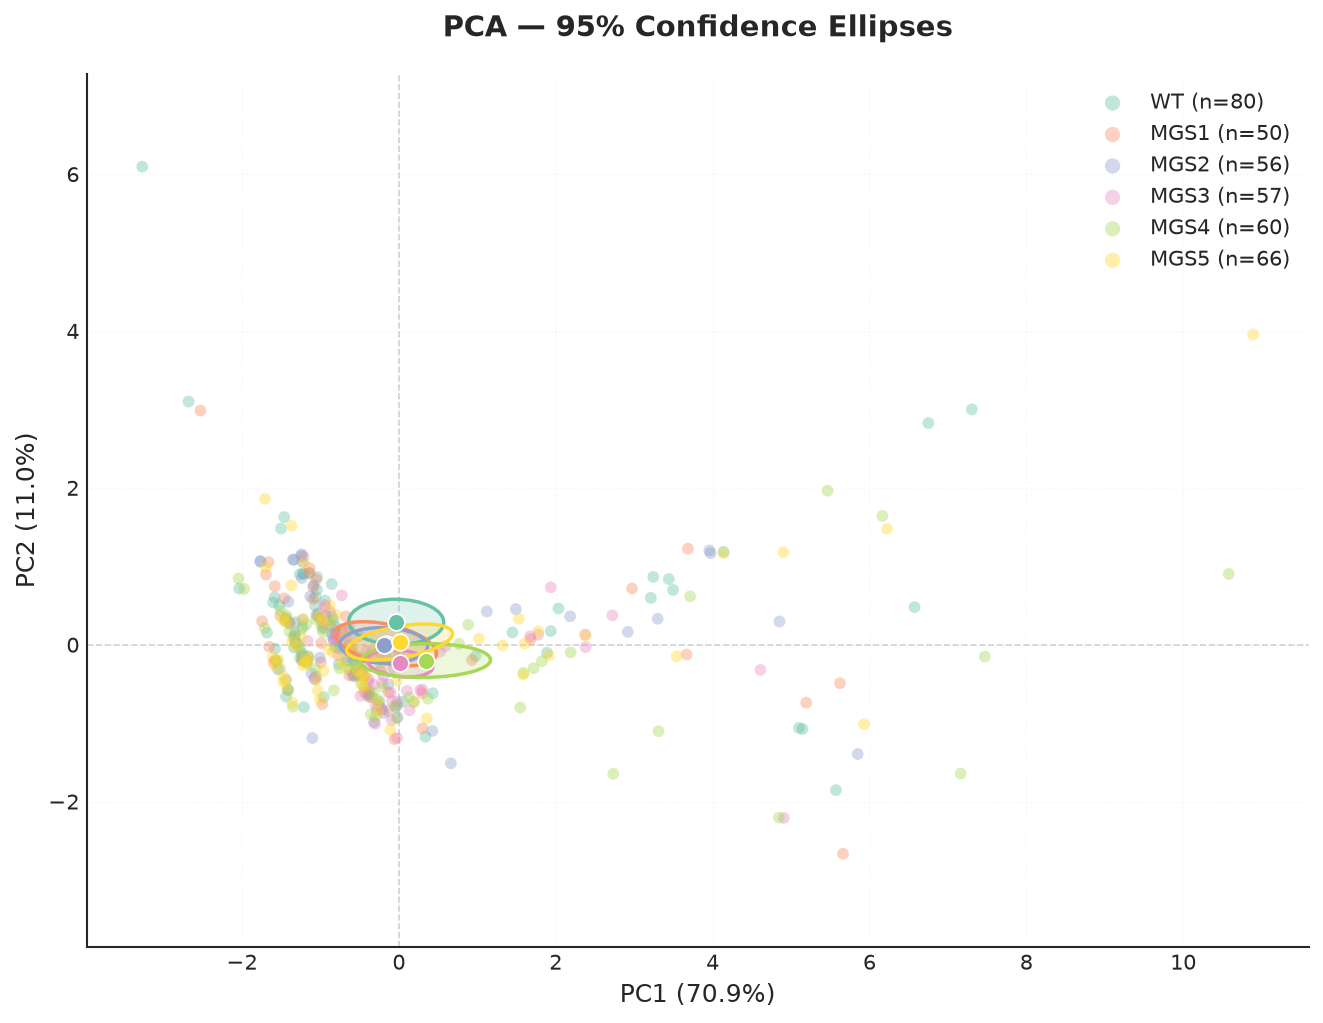

In [14]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    pca=pca,
    confidence=0.95,
    palette="Set2",
    centroid_size=65,
    show_bootstrap=False
)

In [15]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,0.934152,0.4678,0.012704,369,6
1,PERMDISP,1.316314,0.2540,NaN,369,6


In [ ]:
subset = pca_df[(pca_df['sample'] == "WT")| (pca_df['sample'] == "MGS3")]

results_stats = pca_permanova(
    subset,
    group_col="experiment"
)

results_stats

### Centroids distances tree

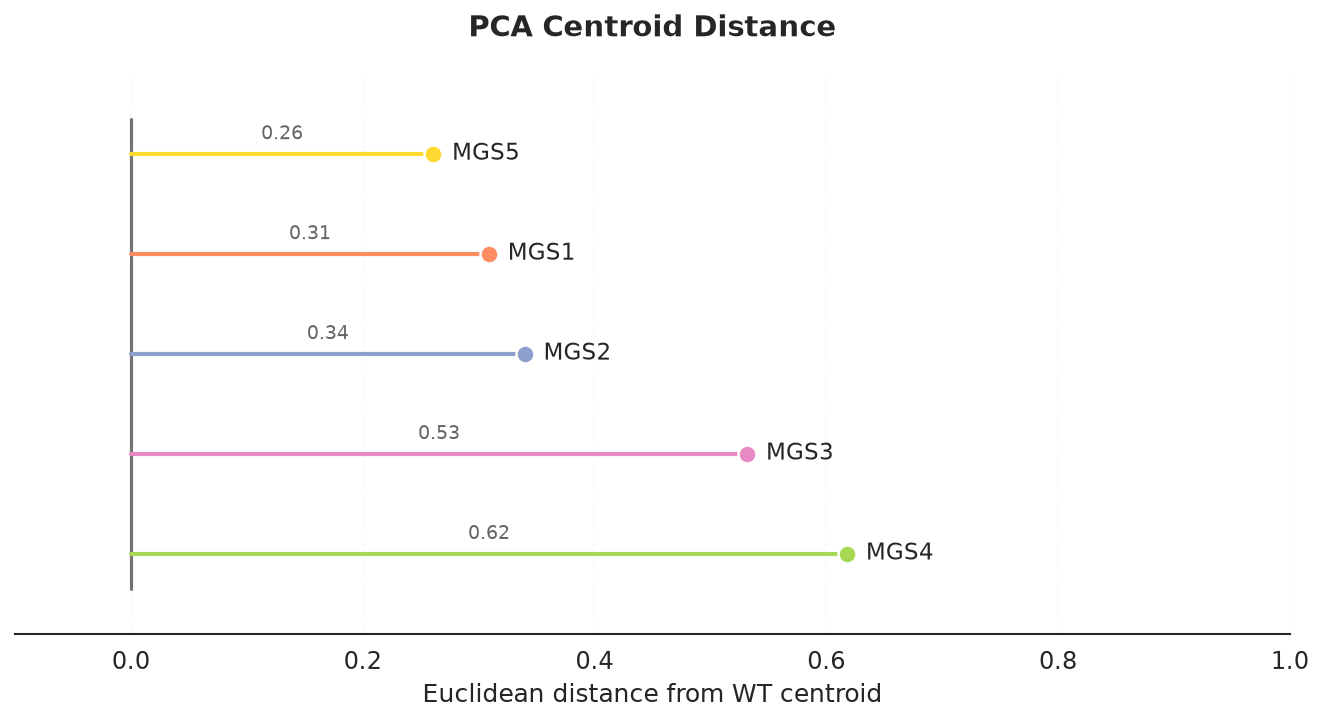

In [16]:
distances = plot_centroid_distance_tree(
    results,
    reference="WT",
    palette="Set2"
)

# Detect outliers

In [17]:
pca_df_outliers = detect_pca_outliers(
    pca_df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
)

# Display detected outliers
outliers = pca_df_outliers[
    pca_df_outliers["outlier"]
]

display(outliers)

,unnamed: 0,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,experiment,PC1,PC2,mahalanobis_distance,outlier
0,0,C2_MP_WT_1.nd2_(series_1)_ROI_0258-0301,1418,4.0,2.256758,0.924176,1.000000,3.414214,1.454545,2.0,1.0,WT,140226,-3.273103,6.095523,5.640994,True
13,13,C2_MP_WT_2.nd2_(series_12)_ROI_0224-0284,8,14.5,4.296101,0.570565,0.970612,11.656854,340.599991,406.0,299.0,WT,140226,5.572278,-1.853871,3.187274,True
36,36,C2_MP_WT_3.nd2_(series_12)_ROI_0271-0275,74,39.5,7.090474,0.796395,0.808256,25.727922,97.708714,126.0,82.0,WT,140226,6.750861,2.826274,3.943159,True
40,40,C2_MP_WT_3.nd2_(series_18)_ROI_0319-0285,57,41.0,7.225152,0.797205,0.775510,26.727922,117.762711,156.0,100.0,WT,140226,7.304857,3.000131,4.245321,True
59,59,C2_MP_MGS1_1.nd2_(series_21)_ROI_0298-0201,837,3.0,1.954410,1.000000,1.000000,2.000000,8.500000,10.0,7.0,MGS1,140226,-2.530442,2.985033,3.644206,True
63,63,C2_MP_MGS1_1.nd2_(series_27)_ROI_0311-0267,3,11.0,3.742410,0.314466,1.000000,9.656854,272.000000,298.0,241.0,MGS1,140226,5.662804,-2.664517,3.749471,True
211,46,C2_MP_U2OS_fixed_MGS1_001.nd2_(series_12)_ROI_...,6,22.0,5.291200,0.680677,0.933684,15.363961,252.120079,315.0,202.0,MGS1,190226,5.622937,-0.490200,3.128181,True
221,56,C2_MP_U2OS_fixed_MGS1_002.nd2_(series_07)_ROI_...,98,13.0,4.068429,0.816497,0.800000,11.639087,64.646294,80.5,55.0,MGS1,190226,3.684676,1.223816,3.282423,True
248,83,C2_MP_U2OS_fixed_MGS2_002.nd2_(series_01)_ROI_...,7,18.0,4.787307,0.584013,0.952381,12.828427,318.500000,393.0,278.0,MGS2,190226,5.849090,-1.393229,3.931370,True
252,87,C2_MP_U2OS_fixed_MGS2_002.nd2_(series_05)_ROI_...,74,15.5,4.441855,0.860487,0.801606,12.156854,98.803032,121.0,85.0,MGS2,190226,3.958404,1.201334,3.046063,True


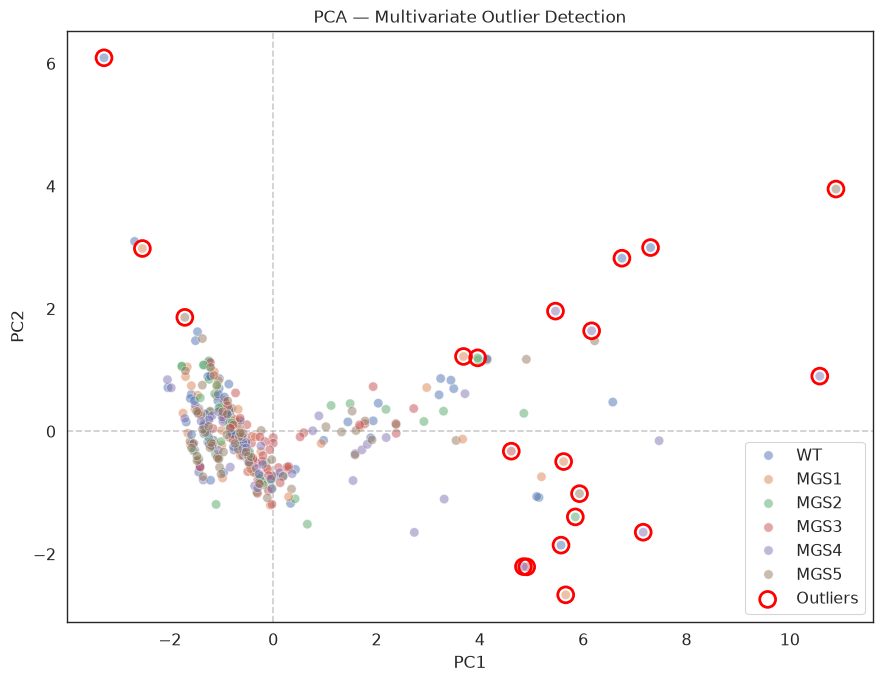

In [18]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_df_outliers,
    x="PC1",
    y="PC2",
    hue="sample",
    alpha=0.5,
    s=45,
    ax=ax
)

# Highlight outliers
outliers = pca_df_outliers[pca_df_outliers["outlier"]]

ax.scatter(
    outliers["PC1"],
    outliers["PC2"],
    s=130,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Outliers"
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)

ax.set_title("PCA — Multivariate Outlier Detection")
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
df_clean = df.loc[~df.index.isin(outliers.index)].copy()
df_clean.shape

(349, 13)

In [ ]:
df_clean = df_clean[~(df_clean['sample'] == 'MGS1')]

In [20]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df_clean.copy()

X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

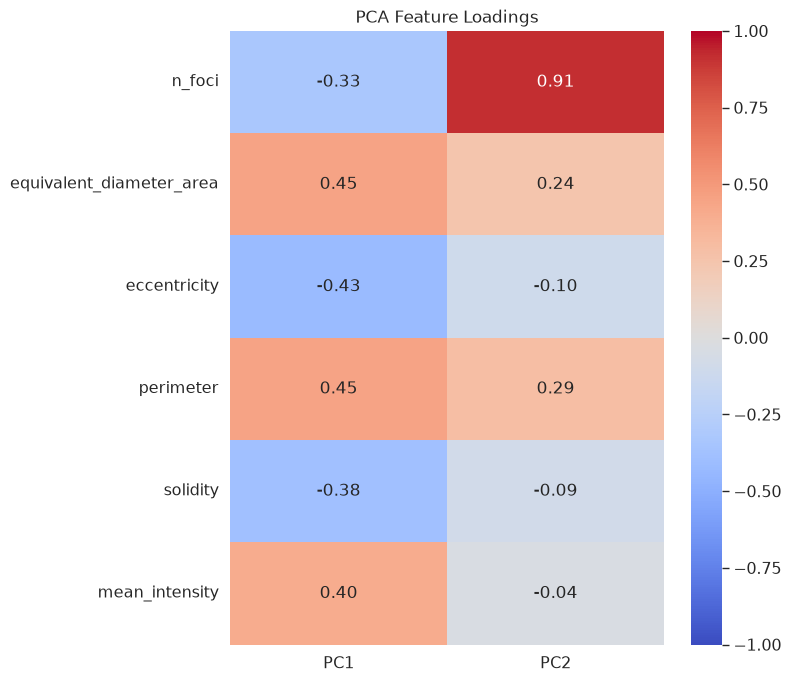

In [21]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

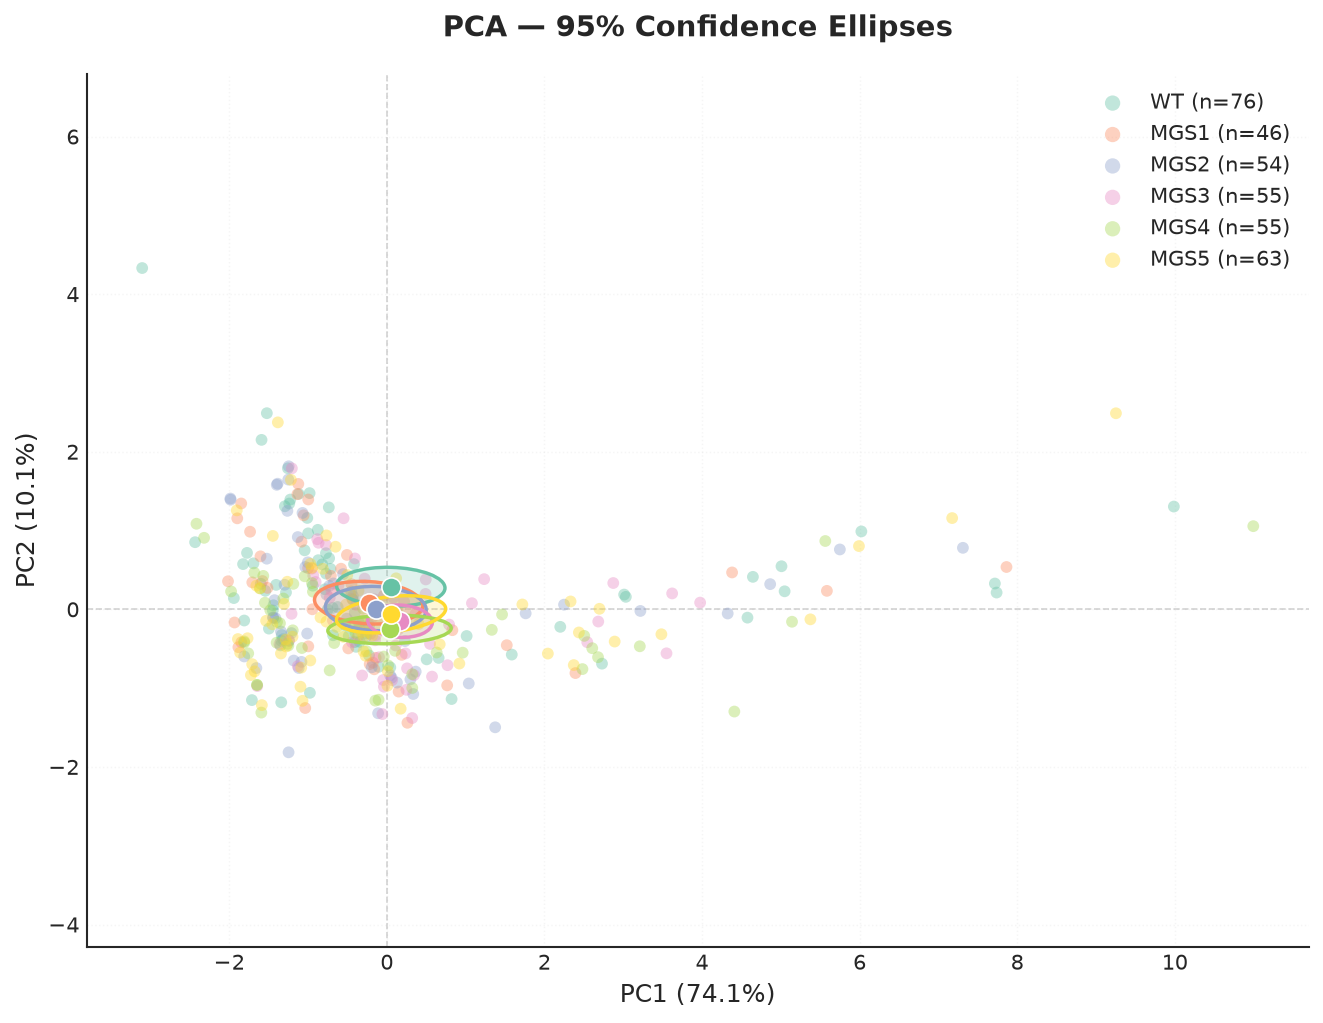

In [22]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

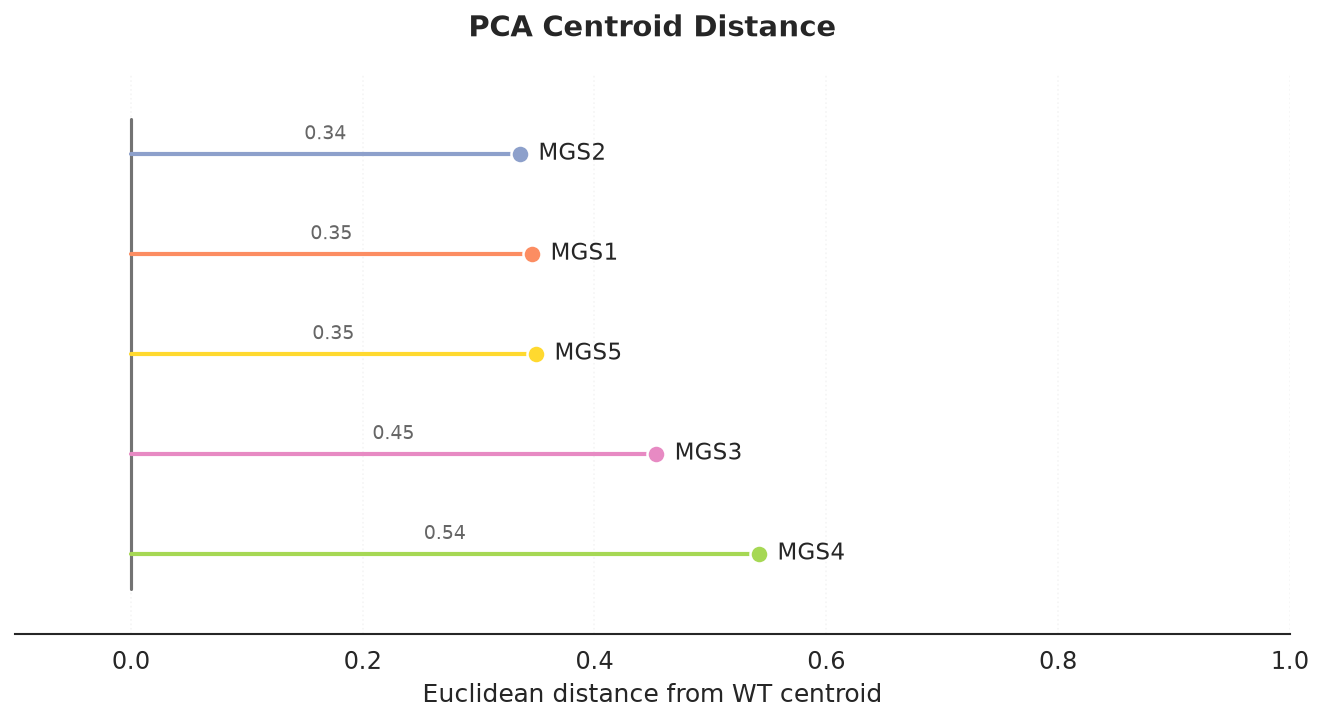

In [23]:
distances = plot_centroid_distance_tree(
    results,
    reference="WT",
    palette="Set2"
)

In [ ]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

In [ ]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "WT") | (pca_df['sample'] == "MGS2")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "WT") | (pca_df['sample'] == "MGS5")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "WT") | (pca_df['sample'] == "MGS3")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "WT") | (pca_df['sample'] == "MGS2")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "WT") | (pca_df['sample'] == "MGS1")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats